# Лабораторная работа №5. Вариант 13
Рясной Владимир Олегович, МИК11.

Постер научной выставки; повтор в одном сеансе. Seed 1013.
Гипотеза: свежие CPU-генераторы дадут одинаковые пиксели и PNG. Допуск: 40 дБ. Время записи гипотезы сохраняется до загрузки модели.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|diffusers|transformers|pillow) "

name, memory.total [MiB]
Tesla T4, 15360 MiB
diffusers                             0.40.0
pillow                                11.3.0
torch                                 2.11.0+cu130
transformers                          5.18.0


In [2]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Writing lab05_lib.py


## Основной эксперимент
Загрузка и прогрев; A/B со свежими генераторами; variant_summary; общий генератор и исправление. Манифесты и метрики сохраняются автоматически.

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


Гипотеза ДО загрузки модели: {
  "recorded_at": "2026-10-18T23:05:39.384862+03:00",
  "variant": 13,
  "seed": 1013,
  "prompt": "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
  "hypothesis": "Свежие CPU-генераторы с seed 1013 в одном сеансе дадут побитово одинаковые изображения. Общий генератор изменит состояние и второе изображение.",
  "tolerance_db": 40.0,
  "decision_rule": "identical: одинаковые пиксели; close: PSNR >= 40 dB; different: PSNR < 40 dB",
  "fixed": {
    "model": "stabilityai/sd-turbo",
    "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
    "size": 512,
    "steps": 1,
    "guidance_scale": 0.0,
    "dtype": "float16",
    "generator_device": "cpu",
    "batch": 1
  }
}
{
  "recorded_at": "2026-10-18T23:05:39.385818+03:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

РЕЗУЛЬТАТЫ: {
  "repeat": {
    "sha_a": "ecccbfce44b9e1a26f3829692028258133ae51c03f7ea8eecb7f77fd309f7a48",
    "sha_b": "ecccbfce44b9e1a26f3829692028258133ae51c03f7ea8eecb7f77fd309f7a48",
    "pixel_equal": true,
    "max_diff": 0,
    "mse": 0.0,
    "psnr": "+Infinity",
    "verdict": "identical"
  },
  "variant_summary": {
    "variant": 13,
    "ctx": 3,
    "cond": "repeat",
    "seed": 1013,
    "sha_a": "ecccbfce44b9e1a26f3829692028258133ae51c03f7ea8eecb7f77fd309f7a48",
    "sha_b": "ecccbfce44b9e1a26f3829692028258133ae51c03f7ea8eecb7f77fd309f7a48",
    "pixel_equal": true,
    "max_diff": 0,
    "psnr": "+Infinity",
    "verdict": "identical",
    "seconds": 0.56,
    "psnr_fixed_noise": null
  },
  "shared_generator": {
    "sha_a": "ecccbfce44b9e1a26f3829692028258133ae51c03f7ea8eecb7f77fd309f7a48",
    "sha_b": "6b4106c8f704a973de86dd75ba074e752a9afec516f1adc71a30891d7b4cf12b",
    "pixel_equal": false,
    "max_diff": 246,
    "mse": 4535.090526580811,
    "psnr": 11.56494

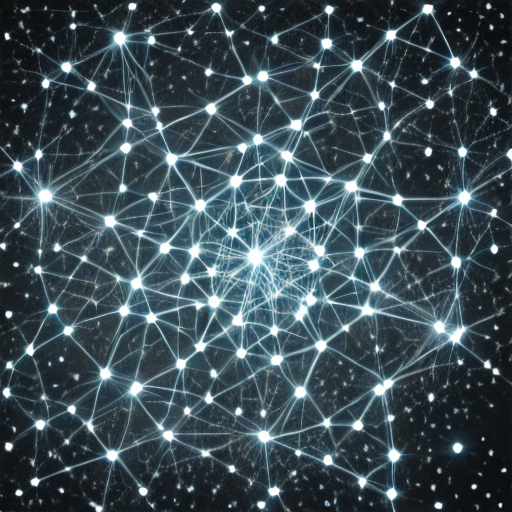

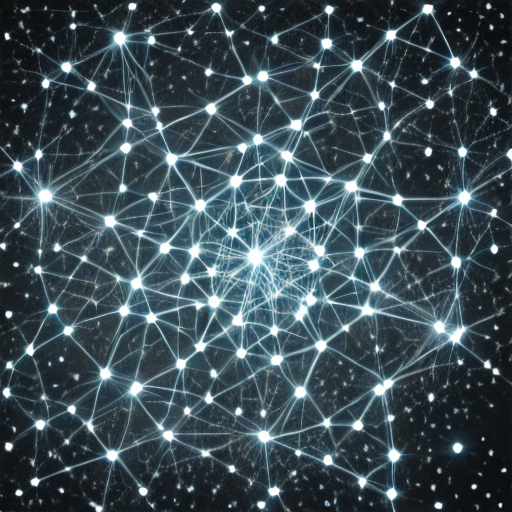

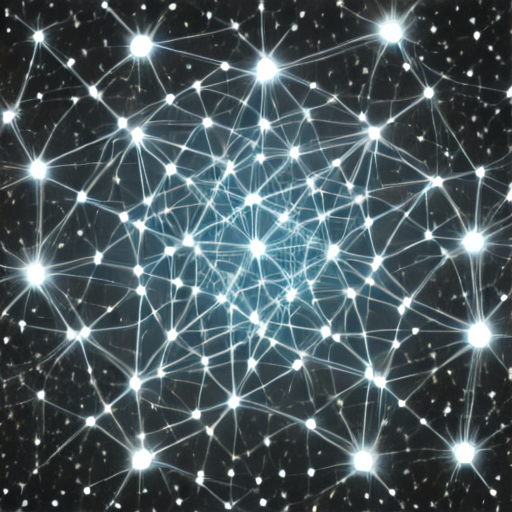

In [3]:
"""ЛР05, вариант 13: запускать в Google Colab с GPU T4 из каталога с lab05_lib.py."""
import contextlib
import datetime as dt
import hashlib
import importlib.metadata as md
import json
import math
import pathlib
import platform
import subprocess
import sys
import time
import numpy as np
import torch
import lab05_lib as L

OUT = pathlib.Path('artifacts')
OUT.mkdir(exist_ok=True)
PROMPT, SEED = L.BRIEFS[2], 1013
TZ = dt.timezone(dt.timedelta(hours=3))
def now():
    return dt.datetime.now(TZ).isoformat()
def save_json(path, obj):
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
def clean(obj):
    if isinstance(obj, dict):
        return {k: clean(v) for k, v in obj.items()}
    if isinstance(obj, float) and not math.isfinite(obj):
        return '+Infinity' if obj > 0 else '-Infinity'
    return obj

def main():
    assert torch.cuda.is_available(), 'Требуется Colab с GPU T4'
    hypothesis = dict(recorded_at=now(), variant=13, seed=SEED, prompt=PROMPT,
        hypothesis='Свежие CPU-генераторы с seed 1013 в одном сеансе дадут побитово одинаковые изображения. Общий генератор изменит состояние и второе изображение.',
        tolerance_db=40.0, decision_rule='identical: одинаковые пиксели; close: PSNR >= 40 dB; different: PSNR < 40 dB',
        fixed=dict(model=L.MODEL_ID, revision=L.REVISION, size=512, steps=1, guidance_scale=0.0, dtype='float16', generator_device='cpu', batch=1))
    save_json(OUT/'expectations_before_run.json', hypothesis)
    print('Гипотеза ДО загрузки модели:', json.dumps(hypothesis,ensure_ascii=False,indent=2), flush=True)
    env = dict(recorded_at=now(), python=sys.version, platform=platform.platform(),
        gpu=torch.cuda.get_device_name(0), cuda=torch.version.cuda,
        cudnn=torch.backends.cudnn.version(), packages={p:md.version(p) for p in ['torch','diffusers','transformers','Pillow','numpy','accelerate','safetensors']},
        library_sha256=hashlib.sha256(pathlib.Path(L.__file__).read_bytes()).hexdigest(),
        nvidia_smi=subprocess.check_output(['nvidia-smi'],text=True))
    save_json(OUT/'environment.json',env)
    print(json.dumps(env,ensure_ascii=False,indent=2),flush=True)
    t0=time.perf_counter(); pipe=L.load_pipe(); torch.cuda.synchronize()
    load_s=time.perf_counter()-t0
    L.generate(pipe,PROMPT,1); torch.cuda.synchronize()
    def run_fresh():
        t=time.perf_counter(); img=L.generate(pipe,PROMPT,SEED)[0]; torch.cuda.synchronize()
        return img,time.perf_counter()-t
    def store(img,label,seconds,generator_policy):
        dest=OUT/label; dest.mkdir(exist_ok=True)
        data=L.png_bytes(img); (dest/'result.png').write_bytes(data)
        manifest=dict(created_at=now(),variant=13,condition=label,model_id=L.MODEL_ID,revision=L.REVISION,
            prompt=PROMPT,seed=SEED,steps=1,guidance_scale=0.0,size=512,batch=1,
            generator_device='cpu',generator_policy=generator_policy,dtype='float16',
            device=env['gpu'],platform=env['platform'],python=sys.version.split()[0],packages=env['packages'],
            load_seconds=load_s,generation_seconds=seconds,image_size=list(img.size),image_mode=img.mode,sha256=L.sha(data))
        save_json(dest/'manifest.json',manifest)
        return manifest
    a,sa=run_fresh(); ma=store(a,'A',sa,'fresh')
    b,sb=run_fresh(); mb=store(b,'B',sb,'fresh')
    def compare(x,y):
        mse=float(np.mean((L.to_arr(x)-L.to_arr(y))**2)); p=L.psnr_db(x,y)
        return clean(dict(sha_a=L.sha(L.png_bytes(x)),sha_b=L.sha(L.png_bytes(y)),
            pixel_equal=bool(np.array_equal(L.to_arr(x),L.to_arr(y))),max_diff=L.max_abs_diff(x,y),mse=mse,psnr=p,verdict=L.classify(p)))
    summary=clean(L.variant_summary(pipe,13))
    result=dict(repeat=compare(a,b),variant_summary=summary)
    g=torch.Generator(device='cpu').manual_seed(SEED)
    state0=L.sha(g.get_state().numpy().tobytes())
    def wrong():
        t=time.perf_counter()
        image=pipe(prompt=[PROMPT],num_inference_steps=1,guidance_scale=0.0,height=512,width=512,generator=g).images[0]
        torch.cuda.synchronize()
        return image,time.perf_counter()-t
    e1,s1=wrong(); state1=L.sha(g.get_state().numpy().tobytes())
    e2,s2=wrong(); state2=L.sha(g.get_state().numpy().tobytes())
    store(e1,'error_first',s1,'shared:first'); store(e2,'error_second',s2,'shared:second')
    fixed,sf=run_fresh(); store(fixed,'corrected',sf,'fresh')
    result.update(shared_generator=compare(e1,e2),error_first_vs_A=compare(a,e1),corrected_vs_A=compare(a,fixed),
        generator_state_sha256=[state0,state1,state2],finished_at=now())
    save_json(OUT/'metrics.json',result)
    print('РЕЗУЛЬТАТЫ:',json.dumps(result,ensure_ascii=False,indent=2),flush=True)
    from IPython.display import display
    display(a); display(b); display(e2)

if __name__=='__main__':
    with (OUT/'run.log').open('w',encoding='utf-8') as log:
        class Tee:
            def write(self,s):
                sys.__stdout__.write(s); log.write(s)
            def flush(self):
                sys.__stdout__.flush(); log.flush()
        # В блокноте stdout должен оставаться IPython-потоком, поэтому журнал ведётся через Tee.
        original=sys.stdout
        class NotebookTee:
            def write(self,s):
                original.write(s); log.write(s)
            def flush(self):
                original.flush(); log.flush()
        with contextlib.redirect_stdout(NotebookTee()):
            main()


## Экспорт первичных результатов
Архив сохраняет изображения, манифесты, гипотезу, среду и журнал.

In [4]:
import shutil
from google.colab import files
shutil.make_archive('lab05_13_artifacts', 'zip', 'artifacts')
files.download('lab05_13_artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>